# TP J4 – UC-08 · Analyse des données et visualisation

**Retail Intelligence Platform** · IPSSI · 19/11/2026 · parcours B (local / open source)

**Objectif** : passer des données Silver et Gold produites au J3 à des **KPI documentés**, des **statistiques
descriptives**, **trois analyses métier** (Q1, Q3, Q5 du J1) et **quatre visualisations** commentées.

**Méthode imposée par le TP** : Spark calcule et agrège, puis seul le **petit tableau de résultat** passe dans Pandas,
et Matplotlib dessine. Aucun `toPandas()` n'est appliqué aux 667 579 lignes de ventes.

> ⚠️ **Données synthétiques.** Elles proviennent du générateur TPCx-BB et sont limitées au **canal magasin**
> (12 magasins, de 2001 au 13/12/2005). Les résultats illustrent une démarche d'analyse : ce ne sont **pas** des
> observations sur une entreprise réelle.

## 1. Bibliothèques et versions

In [1]:
%matplotlib inline
import sys, platform, calendar
from pathlib import Path
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import pyspark
from pyspark.sql import functions as F

BASE = Path.cwd().parents[1]                       # J4/J4_Retail_Intelligence
J1 = BASE.parents[1] / "J1" / "J1_Retail_Intelligence"
J3 = BASE.parents[1] / "J3" / "J3_Retail_Intelligence"
OUT = BASE / "analytics" / "outputs"
VIZ = BASE / "analytics" / "visualizations"
OUT.mkdir(parents=True, exist_ok=True); VIZ.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(BASE / "analytics" / "scripts"))
import kpi_retail as K                             # définitions des KPI (source unique)

BLEU, ORANGE, GRIS = "#2f6db5", "#d9822b", "#555555"
SOURCE = "Source : Retail Intelligence Platform, zone {} (HDFS), données TPCx-BB synthétiques, canal magasin, 12 magasins."
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "text.parse_math": False})          # "$" = dollar, pas une formule

def fr(v, d=0):
    # nombre au format français : espace pour les milliers, virgule décimale
    return f"{v:,.{d}f}".replace(",", " ").replace(".", ",")

print("Python     :", platform.python_version())
print("PySpark    :", pyspark.__version__)
print("Pandas     :", pd.__version__)
print("Matplotlib :", matplotlib.__version__)
print("Noyau      :", sys.executable)

Python     : 3.12.3
PySpark    : 4.3.0
Pandas     : 2.3.3
Matplotlib : 3.11.2
Noyau      : /home/meddy/retail-intelligence/tp3/.venv/bin/python


## 2. Session Spark

In [2]:
spark = K.spark_session("TP4-Retail-Intelligence")
print("Version Spark :", spark.version, "| master :", spark.sparkContext.master,
      "| cœurs :", spark.sparkContext.defaultParallelism)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/19 14:31:43 WARN Utils: Your hostname, Meddy, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/19 14:31:43 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/19 14:31:44 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Version Spark : 4.3.0 | master : local[*] | cœurs : 12


## 3. Chargement des jeux de données (étape 1)

On utilise **3 jeux Silver** et **2 jeux Gold** produits au J3 dans HDFS. On n'utilise aucune autre donnée : pas de
web, pas de retours, pas de stocks, car ces tables n'ont pas été transformées au J3.

In [3]:
jeux = {
    ("Silver", "store_sales"): f"{K.SILVER}/store_sales",
    ("Silver", "item"):        f"{K.SILVER}/item",
    ("Silver", "store"):       f"{K.SILVER}/store",
    ("Gold", "ventes_mensuelles_categorie"):  f"{K.GOLD}/ventes_mensuelles_categorie",
    ("Gold", "performance_magasin_annuelle"): f"{K.GOLD}/performance_magasin_annuelle",
}
df = {nom: spark.read.parquet(chemin) for (_, nom), chemin in jeux.items()}
ventes = df["store_sales"]; g1 = df["ventes_mensuelles_categorie"]; g2 = df["performance_magasin_annuelle"]
for nom in ["store_sales", "ventes_mensuelles_categorie", "performance_magasin_annuelle"]:
    print(f"--- {nom}"); df[nom].printSchema()

--- store_sales
root
 |-- ss_sold_date_sk: integer (nullable = true)
 |-- ss_ticket_number: long (nullable = true)
 |-- ss_item_sk: integer (nullable = true)
 |-- ss_sold_time_sk: integer (nullable = true)
 |-- ss_customer_sk: integer (nullable = true)
 |-- ss_cdemo_sk: integer (nullable = true)
 |-- ss_hdemo_sk: integer (nullable = true)
 |-- ss_addr_sk: integer (nullable = true)
 |-- ss_store_sk: integer (nullable = true)
 |-- ss_promo_sk: integer (nullable = true)
 |-- ss_quantity: integer (nullable = true)
 |-- ss_wholesale_cost: decimal(7,2) (nullable = true)
 |-- ss_list_price: decimal(7,2) (nullable = true)
 |-- ss_sales_price: decimal(7,2) (nullable = true)
 |-- ss_ext_discount_amt: decimal(7,2) (nullable = true)
 |-- ss_ext_sales_price: decimal(7,2) (nullable = true)
 |-- ss_ext_wholesale_cost: decimal(7,2) (nullable = true)
 |-- ss_ext_list_price: decimal(7,2) (nullable = true)
 |-- ss_ext_tax: decimal(7,2) (nullable = true)
 |-- ss_coupon_amt: decimal(7,2) (nullable = true)


## 4. Vérification des volumes, des granularités et de la qualité (étape 1)

Pour chaque jeu, on **vérifie** la granularité au lieu de la supposer : la clé du grain doit être unique.

In [4]:
grains = {
    "store_sales": ["ss_ticket_number", "ss_item_sk"],   # clé candidate testée au J3
    "item": ["i_item_sk"],
    "store": ["s_store_sk"],
    "ventes_mensuelles_categorie": ["annee", "mois", "categorie"],
    "performance_magasin_annuelle": ["annee", "ss_store_sk"],
}
libelle_grain = {
    "store_sales": "1 ligne d'article d'un ticket de caisse (pas de clé unique)",
    "item": "1 produit (version courante)",
    "store": "1 magasin",
    "ventes_mensuelles_categorie": "1 mois x 1 catégorie",
    "performance_magasin_annuelle": "1 année x 1 magasin",
}
usage = {
    "store_sales": "KPI, statistiques, distribution des tickets",
    "item": "catégorie du produit (Q3)",
    "store": "nom et État du magasin (Q5)",
    "ventes_mensuelles_categorie": "Analyse 1 (Q1, évolution) et Analyse 2 (Q3, catégories)",
    "performance_magasin_annuelle": "Analyse 3 (Q5, magasins)",
}
lignes = []
for (zone, nom), chemin in jeux.items():
    d = df[nom]; n = d.count()
    n_cle = d.select(*grains[nom]).distinct().count()
    lignes.append({"jeu": nom, "zone": zone, "chemin_hdfs": chemin.replace(K.HDFS, ""), "format": "Parquet (snappy)",
                   "lignes": n, "colonnes": len(d.columns), "granularite": libelle_grain[nom],
                   "cle_du_grain": " + ".join(grains[nom]), "grain_unique": n == n_cle, "usage": usage[nom]})
inventaire = pd.DataFrame(lignes)
inventaire.to_csv(OUT / "inventaire_jeux.csv", index=False, sep=";")
inventaire

,jeu,zone,chemin_hdfs,format,lignes,colonnes,granularite,cle_du_grain,grain_unique,usage
0,store_sales,Silver,/retail-lake/silver/tpcxbb/store_sales,Parquet (snappy),667579,33,1 ligne d'article d'un ticket de caisse (pas d...,ss_ticket_number + ss_item_sk,False,"KPI, statistiques, distribution des tickets"
1,item,Silver,/retail-lake/silver/tpcxbb/item,Parquet (snappy),17820,27,1 produit (version courante),i_item_sk,True,catégorie du produit (Q3)
2,store,Silver,/retail-lake/silver/tpcxbb/store,Parquet (snappy),12,36,1 magasin,s_store_sk,True,nom et État du magasin (Q5)
3,ventes_mensuelles_categorie,Gold,/retail-lake/gold/retail/ventes_mensuelles_cat...,Parquet (snappy),540,15,1 mois x 1 catégorie,annee + mois + categorie,True,"Analyse 1 (Q1, évolution) et Analyse 2 (Q3, ca..."
4,performance_magasin_annuelle,Gold,/retail-lake/gold/retail/performance_magasin_a...,Parquet (snappy),60,18,1 année x 1 magasin,annee + ss_store_sk,True,"Analyse 3 (Q5, magasins)"


**Le couple (ticket, article) n'est pas une clé des ventes.** Le J3 a montré que 4 136 lignes partagent ce couple
avec une autre ligne, tout en étant des ventes différentes (`_flag_cle_partagee`). Le grain réel est donc la
**ligne de ticket**.

Ce qui compte pour les KPI, c'est le **ticket** : il faut vérifier qu'il représente bien **une transaction**.

In [5]:
t = (ventes.groupBy("ss_ticket_number")
     .agg(F.countDistinct("ss_store_sk").alias("magasins"), F.countDistinct("ss_sold_date_sk").alias("dates"),
          F.countDistinct("ss_customer_sk").alias("clients"), F.count("*").alias("lignes")))
t.agg(F.count("*").alias("tickets"), F.max("magasins").alias("max_magasins_par_ticket"),
      F.max("dates").alias("max_dates_par_ticket"), F.max("clients").alias("max_clients_par_ticket"),
      F.round(F.avg("lignes"), 2).alias("lignes_par_ticket"), F.max("lignes").alias("max_lignes")).show()

+-------+-----------------------+--------------------+----------------------+-----------------+----------+
|tickets|max_magasins_par_ticket|max_dates_par_ticket|max_clients_par_ticket|lignes_par_ticket|max_lignes|
+-------+-----------------------+--------------------+----------------------+-----------------+----------+
|  89100|                      1|                   1|                     1|             7.49|        14|
+-------+-----------------------+--------------------+----------------------+-----------------+----------+



Un ticket correspond à **un seul magasin, une seule date et un seul client**, avec 7,5 lignes en moyenne. Le nombre
de tickets distincts est donc un vrai **nombre de transactions**, et le panier moyen est calculable. Le TP interdit
de le calculer avec un simple nombre de lignes : ici, ce serait 7,5 fois trop petit.

**Contrôles qualité disponibles** : rapport du J3, relu tel quel, sans recalcul.

In [6]:
qualite = pd.read_csv(J3 / "preuves" / "08_rapport_qualite.csv", sep=";")
print(qualite["statut"].value_counts().to_string())
qualite[qualite["statut"] != "OK"][["jeu", "regle", "resultat", "statut"]]

statut
OK        24
ALERTE     7


,jeu,regle,resultat,statut
8,silver/item,marque renseignée (non utilisée en Gold),6 nulle(s) sur 17820,ALERTE
14,silver/store_sales,"clé candidate (ticket, article)","non unique : 4136 ligne(s) en surplus, 8174 li...",ALERTE
16,silver/store_sales,"marge nette négative (conservée, signalée)",495971 lignes (74.3 %),ALERTE
17,silver/store_sales,"montants atypiques Tukey (conservés, signalés)",11910 lignes (1.78 %),ALERTE
18,silver/store_sales,ventes à 0 (remise totale ?),3954 lignes,ALERTE
19,silver/store,date de fermeture exploitable,0/12 fiable(s) ; {'incoherente_avant_ventes': ...,ALERTE
23,silver/store_sales,période couverte,2001-01-01 -> 2005-12-13 (2005 incomplète),ALERTE


Les 7 alertes du J3 **conditionnent l'analyse** :
- **2005 incomplète** : les comparaisons annuelles portent sur 2001-2004, ou sont faites à période égale (01/01 → 13/12).
- **Marge négative sur 74 % des lignes** : aucun KPI de marge n'est publié.
- **Date de fermeture des magasins inutilisable** : tous les magasins sont traités comme ouverts pendant toute la période.

## 5. Calcul des KPI (étape 2)

Les formules viennent de `analytics/scripts/kpi_retail.py`. Elles reprennent le dictionnaire du J1 (KPI-01 à KPI-06),
limité au canal magasin.

In [7]:
kpi_annee = K.kpis(ventes, ["annee"]).toPandas()
for c in ["ca_brut", "ca_net_paye", "panier_moyen_net", "panier_moyen_brut", "taux_remise_pct", "lignes_par_transaction"]:
    kpi_annee[c] = kpi_annee[c].astype(float)

# KPI-06 : évolution N/N-1, sur l'année entière puis à période égale (01/01 -> 13/12)
kpi_egale = K.kpis(K.periode_egale(ventes), ["annee"]).toPandas()
kpi_annee["evol_ca_net_pct"] = (kpi_annee["ca_net_paye"].pct_change() * 100).round(2)
kpi_annee["evol_ca_brut_pct"] = (kpi_annee["ca_brut"].pct_change() * 100).round(2)
kpi_annee["ca_net_periode_egale"] = kpi_egale["ca_net_paye"].astype(float).values
kpi_annee["evol_ca_net_periode_egale_pct"] = (kpi_annee["ca_net_periode_egale"].pct_change() * 100).round(2)
kpi_annee["annee_complete"] = kpi_annee["annee"] <= K.ANNEES_COMPLETES[1]
kpi_annee.to_csv(OUT / "kpi.csv", index=False, sep=";", decimal=",")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
kpi_annee.set_index("annee").T

annee,2001,2002,2003,2004,2005
ca_brut,258 159 395.33,256 977 671.52,259 060 054.76,260 029 656.73,242 997 226.27
ca_net_paye,232 498 659.83,230 947 265.82,233 575 185.63,234 344 934.29,219 163 540.80
nb_transactions,17991,17990,17990,18039,17090
nb_lignes,134873,135084,134773,136014,126835
quantites,6814234,6825340,6820308,6887086,6408506
panier_moyen_net,12 923.05,12 837.54,12 983.61,12 991.02,12 824.08
panier_moyen_brut,14 349.36,14 284.47,14 400.23,14 414.86,14 218.68
lignes_par_transaction,7.50,7.51,7.49,7.54,7.42
taux_remise_pct,49.97,50.16,49.83,50.03,49.96
evol_ca_net_pct,NaN,-0.67,1.14,0.33,-6.48


### Contrôle de cohérence n° 1 : réconciliation avec les valeurs de test du J1

Au J1, les mêmes KPI avaient été calculés avec Pandas **directement sur les fichiers `.dat` bruts**
(`UC01_dictionnaire_KPI.xlsx`, onglet `Test_annee_canal`). Si le nettoyage du J3 n'a rien perdu ni déformé, on doit
retrouver **exactement** les mêmes valeurs à partir du Silver.

In [8]:
j1 = pd.read_excel(J1 / "01_UC01_besoin_exploration" / "UC01_dictionnaire_KPI.xlsx", sheet_name="Test_annee_canal")
j1 = j1[j1["canal"] == "magasin"].set_index("annee")
correspondance = {"CA_brut (ext_sales_price)": "ca_brut", "CA_net_paye (net_paid)": "ca_net_paye",
                  "Nb_transactions": "nb_transactions", "Nb_lignes": "nb_lignes",
                  "Quantites_vendues": "quantites", "Panier_moyen": "panier_moyen_brut",
                  "Taux_remise_%": "taux_remise_pct", "Evolution_CA_vs_N-1_%": "evol_ca_brut_pct"}
j4 = kpi_annee.set_index("annee")
rec = []
for col_j1, col_j4 in correspondance.items():
    for an in j4.index:
        v1, v4 = j1.loc[an, col_j1], j4.loc[an, col_j4]
        if pd.isna(v1) and pd.isna(v4):
            continue
        rec.append({"kpi": col_j4, "annee": an, "J1_brut_pandas": float(v1), "J4_silver_spark": float(v4),
                    "ecart": round(float(v4) - float(v1), 2)})
rec = pd.DataFrame(rec)
rec.to_csv(OUT / "reconciliation_j1_j4.csv", index=False, sep=";", decimal=",")
print(f"{len(rec)} comparaisons, écart absolu maximal : {rec['ecart'].abs().max()}")
assert rec["ecart"].abs().max() == 0, "écart entre J1 et J4"
rec.pivot(index="kpi", columns="annee", values="ecart")

39 comparaisons, écart absolu maximal : 0.0


annee,2001,2002,2003,2004,2005
kpi,,,,,
ca_brut,0.00,0.00,0.00,0.00,0.00
ca_net_paye,0.00,0.00,0.00,0.00,0.00
evol_ca_brut_pct,NaN,0.00,0.00,0.00,0.00
nb_lignes,0.00,0.00,0.00,0.00,0.00
nb_transactions,0.00,0.00,0.00,0.00,0.00
panier_moyen_brut,0.00,0.00,0.00,0.00,0.00
quantites,0.00,0.00,0.00,0.00,0.00
taux_remise_pct,0.00,0.00,0.00,0.00,0.00


**39 comparaisons (8 KPI × 5 ans, sans l'évolution de 2001), 0 écart.** Les KPI calculés par Spark sur le Silver sont identiques, au centime près, à ceux
calculés au J1 par Pandas sur les fichiers bruts. Les définitions sont donc stables et le nettoyage n'a rien changé
aux montants.

### Contrôle de cohérence n° 2 : Gold = Silver

Les analyses 1 et 2 utilisent le Gold G1, et l'analyse 3 le Gold G2. Leurs totaux doivent être égaux à ceux du Silver.

In [9]:
tot_silver = ventes.agg(F.sum("ss_net_paid").alias("ca"), F.sum("ss_quantity").alias("q")).first()
tot_g1 = g1.agg(F.sum("ca_net_paid").alias("ca"), F.sum("quantite").alias("q")).first()
tot_g2 = g2.agg(F.sum("ca_net_paid").alias("ca"), F.sum("quantite").alias("q")).first()
controle = pd.DataFrame({"Silver": [tot_silver.ca, tot_silver.q], "Gold G1": [tot_g1.ca, tot_g1.q],
                         "Gold G2": [tot_g2.ca, tot_g2.q]}, index=["CA net payé", "Quantités"])
assert tot_silver.ca == tot_g1.ca == tot_g2.ca and tot_silver.q == tot_g1.q == tot_g2.q
controle

,Silver,Gold G1,Gold G2
CA net payé,1150529586.37,1150529586.37,1150529586.37
Quantités,33755474,33755474,33755474


## 6. Statistiques descriptives (étape 3)

Elles sont calculées à deux grains, **ligne de ticket** et **ticket**, parce qu'une moyenne ne veut rien dire sans
son grain. Les quartiles sont **exacts** (`percentile`, et non une approximation). La somme n'est donnée que pour les
mesures additives.

In [10]:
def stats(d, colonnes, grain, additives):
    res = []
    for c in colonnes:
        x = F.col(c).cast("double")
        r = d.agg(F.count(c).alias("n"), F.sum(F.col(c).isNull().cast("int")).alias("nuls"),
                  F.min(x).alias("min"), F.expr(f"percentile(cast({c} as double), array(0.25, 0.5, 0.75))").alias("q"),
                  F.avg(x).alias("moyenne"), F.max(x).alias("max"), F.stddev(x).alias("ecart_type"),
                  F.sum(x).alias("somme")).first()
        res.append({"grain": grain, "variable": c, "n": r.n, "nuls": r.nuls, "min": r["min"], "q1": r.q[0],
                    "mediane": r.q[1], "moyenne": r.moyenne, "q3": r.q[2], "max": r["max"],
                    "ecart_type": r.ecart_type, "somme": r.somme if c in additives else None})
    return res

par_ticket = (ventes.groupBy("ss_store_sk", "ss_ticket_number")
              .agg(F.sum("ss_net_paid").alias("montant_ticket"), F.count("*").alias("lignes_ticket"),
                   F.sum("ss_quantity").alias("articles_ticket")))
mesures = ["ss_quantity", "ss_sales_price", "ss_ext_sales_price", "ss_ext_discount_amt", "ss_net_paid"]
statistiques = pd.DataFrame(
    stats(ventes, mesures, "ligne de ticket", {"ss_quantity", "ss_ext_sales_price", "ss_ext_discount_amt", "ss_net_paid"})
    + stats(par_ticket, ["montant_ticket", "lignes_ticket", "articles_ticket"], "ticket",
            {"montant_ticket", "articles_ticket"}))
statistiques.to_csv(OUT / "statistiques.csv", index=False, sep=";", decimal=",")
statistiques

,grain,variable,n,nuls,min,q1,mediane,moyenne,q3,max,ecart_type,somme
0,ligne de ticket,ss_quantity,667579,0,1.00,26.00,51.00,50.56,76.00,100.00,28.88,33 755 474.00
1,ligne de ticket,ss_sales_price,667579,0,0.00,10.25,27.69,37.86,56.78,199.30,34.40,NaN
2,ligne de ticket,ss_ext_sales_price,667579,0,0.00,313.56,1 048.50,1 913.22,2 674.44,18 745.00,2 281.75,1 277 224 004.61
3,ligne de ticket,ss_ext_discount_amt,667579,0,0.00,313.25,1 046.73,1 912.45,2 669.27,18 984.00,2 282.66,1 276 714 271.73
4,ligne de ticket,ss_net_paid,667579,0,0.00,245.70,878.54,1 723.44,2 366.51,18 745.00,2 167.90,1 150 529 586.37
5,ticket,montant_ticket,89100,0,0.00,5 572.46,11 645.15,12 912.79,18 791.10,64 785.95,9 063.74,1 150 529 586.37
6,ticket,lignes_ticket,89100,0,1.00,4.00,7.00,7.49,11.00,14.00,4.02,NaN
7,ticket,articles_ticket,89100,0,1.00,194.00,372.00,378.85,550.00,1 143.00,217.36,33 755 474.00


**Lecture des statistiques.**

- **Grain ligne.** La quantité va de 1 à 100 (médiane 51). Le prix unitaire va de 0 à 199,30 \\$. Le montant net payé d'une ligne a une médiane de 879 \\$, mais une moyenne de 1 723 \\$ : la distribution est **asymétrique**, car quelques grosses lignes tirent la moyenne vers le haut. La médiane est donc plus représentative.
- **Remise.** La somme des remises (1 276,7 M\\$) est presque égale au CA brut (1 277,2 M\\$). C'est cohérent avec un taux de remise de 50 % du prix catalogue.
- **Grain ticket.** On compte 89 100 tickets, avec en médiane 7 lignes, 372 articles et 11 645 \\$ par ticket. **372 articles par ticket n'est pas réaliste** pour un magasin : c'est un effet du générateur, qui tire la quantité de chaque ligne au hasard entre 1 et 100. Ces valeurs ne doivent pas servir de référence métier.
- **Cohérence.** La somme de `ss_net_paid` est égale à la somme des montants par ticket : 1 150 529 586,37 \\$.

## 7. Analyse 1 – Q1 : comment évolue le chiffre d'affaires dans le temps ? (étapes 4 et 5)

- **Données** : Gold `ventes_mensuelles_categorie`, sommé sur les 9 catégories, ce qui donne 60 mois.
- **Méthode** : CA net payé par mois. On calcule ensuite un **indice saisonnier** sur 2001-2004 : CA moyen du mois
  divisé par le CA mensuel moyen, multiplié par 100.

In [11]:
mensuel = (g1.groupBy("annee", "mois")
           .agg(F.sum("ca_net_paid").alias("ca_net_paye"), F.sum("quantite").alias("quantites"),
                F.sum("nb_tickets").alias("nb_tickets"), F.min(F.col("mois_complet").cast("int")).alias("mois_complet"))
           .orderBy("annee", "mois")).toPandas()
mensuel["ca_net_paye"] = mensuel["ca_net_paye"].astype(float)
mensuel["mois_complet"] = mensuel["mois_complet"].astype(bool)
pleines = mensuel[mensuel["annee"].between(*K.ANNEES_COMPLETES)]
indice = (pleines.groupby("mois")["ca_net_paye"].mean() / pleines["ca_net_paye"].mean() * 100).round(1)
mensuel["indice_saisonnier_mois"] = mensuel["mois"].map(indice)
# même indice ramené au nombre de jours vendus du mois (13 jours pour décembre 2005)
mensuel["jours"] = [13 if not c else calendar.monthrange(a, m)[1]
                    for a, m, c in zip(mensuel["annee"], mensuel["mois"], mensuel["mois_complet"])]
mensuel["ca_par_jour"] = (mensuel["ca_net_paye"] / mensuel["jours"]).round(2)
pleines = mensuel[mensuel["annee"].between(*K.ANNEES_COMPLETES)]
indice_jour = (pleines.groupby("mois")["ca_par_jour"].mean() / pleines["ca_par_jour"].mean() * 100).round(1)
mensuel["indice_saisonnier_par_jour"] = mensuel["mois"].map(indice_jour)
mensuel.to_csv(OUT / "analyse1_ca_mensuel.csv", index=False, sep=";", decimal=",")
print("Mois incomplets :", mensuel.loc[~mensuel["mois_complet"], ["annee", "mois"]].values.tolist())
print("Indice saisonnier 2001-2004 (base 100 = mois moyen), brut puis ramené au nombre de jours :")
print(pd.DataFrame({"indice_mois": indice, "indice_par_jour": indice_jour}).T.to_string())
cj = pleines["ca_par_jour"]
print(f"CA par jour 2001-2004 : de {fr(cj.min())} à {fr(cj.max())} $ ; décembre 2005 (13 jours) : "
      f"{fr(mensuel['ca_par_jour'].iloc[-1])} $ par jour")

Mois incomplets : [[2005, 12]]
Indice saisonnier 2001-2004 (base 100 = mois moyen), brut puis ramené au nombre de jours :
mois                1      2      3     4      5      6      7      8      9      10    11     12
indice_mois     100.60  93.10 102.00 98.10 101.50  98.90 102.80 101.80  98.50 102.90 98.40 101.30
indice_par_jour  98.80 100.30 100.20 99.50  99.70 100.30 101.00 100.00 100.00 101.00 99.90  99.50
CA par jour 2001-2004 : de 617 575 à 670 303 $ ; décembre 2005 (13 jours) : 621 401 $ par jour


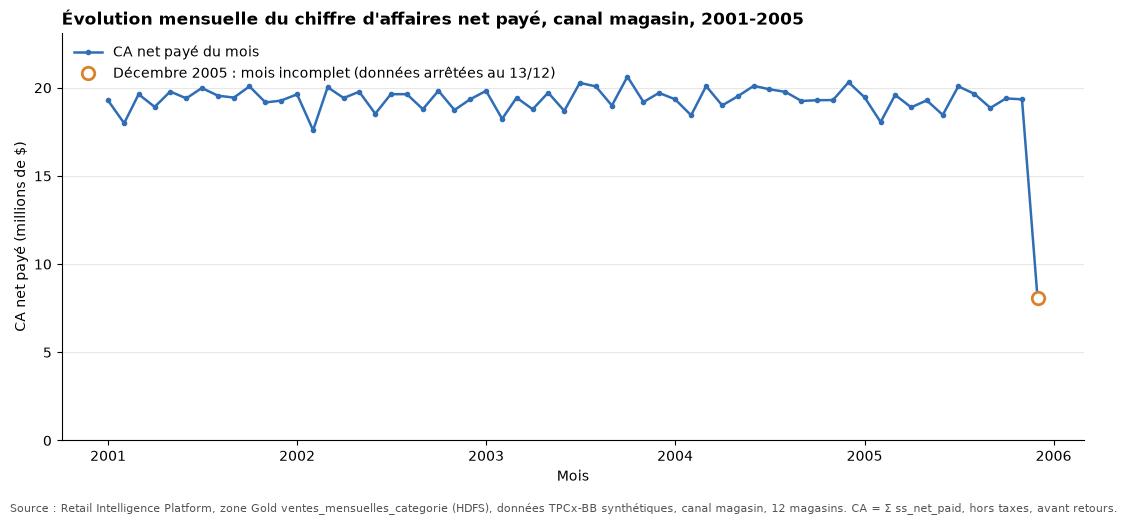

In [12]:
x = pd.to_datetime(dict(year=mensuel["annee"], month=mensuel["mois"], day=1))
y = mensuel["ca_net_paye"] / 1e6
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.plot(x, y, color=BLEU, lw=1.8, marker="o", ms=3, label="CA net payé du mois")
inc = ~mensuel["mois_complet"]
ax.plot(x[inc], y[inc], ls="none", marker="o", ms=9, mfc="white", mec=ORANGE, mew=2,
        label="Décembre 2005 : mois incomplet (données arrêtées au 13/12)")
ax.set_title("Évolution mensuelle du chiffre d'affaires net payé, canal magasin, 2001-2005", loc="left", fontweight="bold")
ax.set_xlabel("Mois")
ax.set_ylabel("CA net payé (millions de $)")
ax.set_ylim(0, y.max() * 1.12)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="upper left")
fig.text(0.01, 0.005, SOURCE.format("Gold ventes_mensuelles_categorie") + " CA = Σ ss_net_paid, hors taxes, avant retours.",
         fontsize=8, color=GRIS)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(VIZ / "evolution_ventes_mensuelles.png", dpi=150, bbox_inches="tight")
plt.show()

**Résultats (Q1).**
- De 2001 à 2004, le CA mensuel varie entre **17,6 M\\$** (février 2002) et **20,6 M\\$** (octobre 2003), **sans tendance**. D'une année sur l'autre : −0,67 %, +1,14 %, +0,33 %.
- L'indice saisonnier brut va de 93,1 (février) à 102,9 (octobre). **Ramené au nombre de jours, il ne varie plus qu'entre 98,8 et 101,0** : les écarts entre mois viennent du calendrier (février n'a que 28 jours), pas d'une saisonnalité.
- La chute de la courbe en décembre 2005 **est un artefact** : le mois ne compte que 13 jours. Le CA par jour est de 621 401 \\$, dans la plage habituelle (617 575 à 670 303 \\$). En année entière, 2005 est à −6,48 %, mais **à période égale (01/01 → 13/12) elle n'est qu'à −1,53 %**.

**Interprétation.** L'activité est plate et sans saisonnalité. Un vrai commerce de musique et de livres aurait un pic en fin d'année : ce profil reflète le générateur synthétique, pas un comportement d'achat. La baisse de 1,5 % en 2005 à période égale est du même ordre que les variations annuelles observées (±1,1 %). Elle est à surveiller, pas à conclure.

**Limites.** Canal magasin seul, CA avant retours, données synthétiques. Le dernier mois est partiel : il est signalé par `mois_complet` dans le Gold.

## 8. Analyse 2 – Q3 : quelles catégories contribuent le plus au chiffre d'affaires ?

- **Données** : Gold `ventes_mensuelles_categorie`, 2001-2004 (années complètes).
- **Méthode** : CA, part du CA, quantités, prix moyen par unité vendue et taux de remise, par catégorie.
- **Complément** : la **concentration par produit**, calculée sur le Silver joint à `item`. Spark agrège d'abord par
  produit, puis on lit les parts cumulées.

In [13]:
cat = (g1.filter(F.col("annee").between(*K.ANNEES_COMPLETES))
       .groupBy("categorie")
       .agg(F.sum("ca_net_paid").alias("ca_net_paye"), F.sum("quantite").alias("quantites"),
            F.sum("nb_lignes").alias("nb_lignes"), F.sum("remise").alias("remise"),
            F.sum("montant_prix_catalogue").alias("prix_catalogue"))
       .orderBy(F.desc("ca_net_paye"))).toPandas()
for c in ["ca_net_paye", "remise", "prix_catalogue"]:
    cat[c] = cat[c].astype(float)
cat["part_ca_pct"] = (cat["ca_net_paye"] / cat["ca_net_paye"].sum() * 100).round(2)
cat["part_quantites_pct"] = (cat["quantites"] / cat["quantites"].sum() * 100).round(2)
cat["ca_par_unite"] = (cat["ca_net_paye"] / cat["quantites"]).round(2)
cat["taux_remise_pct"] = (cat["remise"] / cat["prix_catalogue"] * 100).round(2)
cat["part_ca_cumulee_pct"] = cat["part_ca_pct"].cumsum().round(2)
nb_prod = df["item"].groupBy(F.col("i_category").alias("categorie")).count().toPandas()
cat = cat.merge(nb_prod.rename(columns={"count": "nb_produits"}), on="categorie")
cat["part_produits_pct"] = (cat["nb_produits"] / cat["nb_produits"].sum() * 100).round(2)
cat["ca_par_produit"] = (cat["ca_net_paye"] / cat["nb_produits"]).round(0)
cat = cat.drop(columns=["remise", "prix_catalogue"])
cat.to_csv(OUT / "analyse2_categories.csv", index=False, sep=";", decimal=",")
cat

,categorie,ca_net_paye,quantites,nb_lignes,part_ca_pct,part_quantites_pct,ca_par_unite,taux_remise_pct,part_ca_cumulee_pct,nb_produits,part_produits_pct,ca_par_produit
0,Music,421 255 749.81,12354032,244064,45.23,45.18,34.10,49.94,45.23,8143,45.70,51 732.00
1,Books,248 183 834.32,7293360,143870,26.65,26.67,34.03,50.06,71.88,5335,29.94,46 520.00
2,Movies & TV,60 835 794.91,1777914,35178,6.53,6.50,34.22,50.00,78.41,1286,7.22,47 306.00
3,Clothing & Accessories,45 733 997.02,1321035,26117,4.91,4.83,34.62,49.52,83.32,610,3.42,74 974.00
4,Electronics,44 888 929.48,1316191,26312,4.82,4.81,34.11,50.14,88.14,692,3.88,64 868.00
5,Home & Kitchen,33 358 520.34,992609,19738,3.58,3.63,33.61,50.22,91.72,476,2.67,70 081.00
6,Sports & Outdoors,33 077 603.08,980342,19384,3.55,3.58,33.74,49.86,95.27,465,2.61,71 135.00
7,Toys & Games,22 289 388.44,660617,13154,2.39,2.42,33.74,50.14,97.66,405,2.27,55 036.00
8,Tools & Home Improvement,21 742 228.17,650868,12927,2.33,2.38,33.40,50.75,99.99,408,2.29,53 290.00


In [14]:
par_produit = (ventes.filter(F.col("sold_year").between(*K.ANNEES_COMPLETES))
               .groupBy("ss_item_sk").agg(F.sum("ss_net_paid").alias("ca")))
n_vendus = par_produit.count()
n_catalogue = df["item"].count()
ca_prod = par_produit.select(F.col("ca").cast("double")).toPandas()["ca"].sort_values(ascending=False).reset_index(drop=True)
part_cum = ca_prod.cumsum() / ca_prod.sum()
conc = pd.DataFrame({"part_des_produits_vendus_pct": [1, 5, 10, 20, 50]})
conc["part_du_ca_pct"] = [round(part_cum.iloc[int(len(ca_prod) * p / 100) - 1] * 100, 1) for p in conc.iloc[:, 0]]
n50 = int((part_cum < 0.5).sum()) + 1
conc.to_csv(OUT / "analyse2_concentration_produits.csv", index=False, sep=";", decimal=",")
print(f"Produits au catalogue : {n_catalogue}, produits vendus en 2001-2004 : {n_vendus}")
print(f"50 % du CA est fait par {n50} produits, soit {n50 / n_vendus * 100:.1f} % des produits vendus")
conc

Produits au catalogue : 17820, produits vendus en 2001-2004 : 17820
50 % du CA est fait par 1087 produits, soit 6.1 % des produits vendus


,part_des_produits_vendus_pct,part_du_ca_pct
0,1,39.40
1,5,48.90
2,10,53.60
3,20,61.70
4,50,80.80


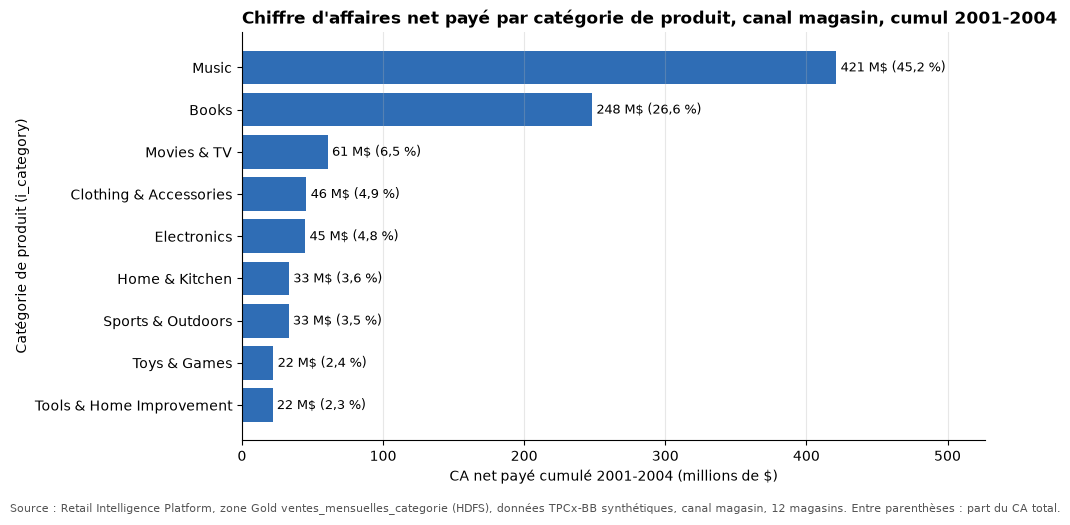

In [15]:
c = cat.sort_values("part_ca_pct")
fig, ax = plt.subplots(figsize=(10, 5.2))
barres = ax.barh(c["categorie"], c["ca_net_paye"] / 1e6, color=BLEU)
for b, part, ca in zip(barres, c["part_ca_pct"], c["ca_net_paye"]):
    ax.text(b.get_width() + 3, b.get_y() + b.get_height() / 2, f"{fr(ca / 1e6)} M$ ({fr(part, 1)} %)",
            va="center", fontsize=9)
ax.set_title("Chiffre d'affaires net payé par catégorie de produit, canal magasin, cumul 2001-2004",
             loc="left", fontweight="bold")
ax.set_xlabel("CA net payé cumulé 2001-2004 (millions de $)")
ax.set_ylabel("Catégorie de produit (i_category)")
ax.set_xlim(0, c["ca_net_paye"].max() / 1e6 * 1.25)
ax.grid(axis="x", alpha=0.3)
fig.text(0.01, 0.005, SOURCE.format("Gold ventes_mensuelles_categorie") + " Entre parenthèses : part du CA total.",
         fontsize=8, color=GRIS)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(VIZ / "ca_par_categorie.png", dpi=150, bbox_inches="tight")
plt.show()

**Résultats (Q3).**
- **Music (45,2 %) et Books (26,6 %) font 71,9 % du CA** de 2001-2004. Les 7 autres catégories pèsent chacune entre 2,3 et 6,5 %.
- La part de CA de chaque catégorie est **presque égale à sa part des quantités** (Music : 45,2 % contre 45,2 %) **et à sa part du catalogue** (Music : 45,7 % des produits ; Books : 29,9 %). Le CA par unité vendue est de 33 à 35 \\$ partout, et le taux de remise de 49,5 à 50,8 %.
- **Concentration par produit** : les 17 820 produits ont tous été vendus. 1 % d'entre eux (178) font 39,4 % du CA, et 6,1 % (1 087) en font la moitié.

**Interprétation.** Ce n'est ni le prix ni la remise qui fait la hiérarchie des catégories, c'est le **nombre de références** : Music domine parce qu'elle a le plus grand catalogue. Le CA moyen **par produit** est même plus élevé dans les petites catégories, par exemple 74 974 \\$ pour Clothing contre 51 732 \\$ pour Music. En revanche, à l'intérieur du catalogue, le CA est très concentré sur un petit nombre de produits.

**Limites.** CA avant retours : `store_returns` n'est pas intégré au Silver. Une analyse plus fine par classe (`i_class`) ou par marque est possible mais non faite ici. La marge n'est pas publiée (alerte qualité du J3).

## 9. Analyse 3 – Q5 : quelles différences observe-t-on entre les magasins ?

- **Données** : Gold `performance_magasin_annuelle`, 2001-2004.
- **Méthode** : on cumule le CA, les tickets et le panier moyen sur 4 ans. On calcule ensuite l'écart de chaque
  magasin au magasin moyen, puis la **stabilité du classement** d'une année à l'autre.

In [16]:
mag = (g2.filter(F.col("annee").between(*K.ANNEES_COMPLETES))
       .groupBy("ss_store_sk", "s_store_name", "s_city", "s_state")
       .agg(F.sum("ca_net_paid").alias("ca_net_paye"), F.sum("nb_tickets").alias("nb_transactions"),
            F.sum("quantite").alias("quantites"))
       .orderBy(F.desc("ca_net_paye"))).toPandas()
mag["ca_net_paye"] = mag["ca_net_paye"].astype(float)
mag["panier_moyen_net"] = (mag["ca_net_paye"] / mag["nb_transactions"]).round(2)
mag["ecart_moyenne_pct"] = ((mag["ca_net_paye"] / mag["ca_net_paye"].mean() - 1) * 100).round(2)
mag["ecart_transactions_pct"] = ((mag["nb_transactions"] / mag["nb_transactions"].mean() - 1) * 100).round(2)
mag["magasin"] = mag["s_store_name"] + " (" + mag["s_state"] + ")"
taille = df["store"].select("s_store_sk", "s_floor_space", "s_number_employees").toPandas()
mag = mag.merge(taille, left_on="ss_store_sk", right_on="s_store_sk").drop(columns="s_store_sk")
rangs = (g2.filter(F.col("annee").between(*K.ANNEES_COMPLETES)).select("annee", "ss_store_sk", "rang_ca_annee")
         .toPandas().pivot(index="ss_store_sk", columns="annee", values="rang_ca_annee"))
mag = mag.merge(rangs.add_prefix("rang_").reset_index(), on="ss_store_sk")
mag.to_csv(OUT / "analyse3_magasins.csv", index=False, sep=";", decimal=",")
cv = mag["ca_net_paye"].std() / mag["ca_net_paye"].mean() * 100
corr_tickets = mag["ca_net_paye"].corr(mag["nb_transactions"])
print(f"Écart entre le 1er et le 12e : {fr(mag['ecart_moyenne_pct'].max() - mag['ecart_moyenne_pct'].min(), 2)} points ;"
      f" coefficient de variation : {fr(cv, 2)} % ; corrélation CA/tickets : {fr(corr_tickets, 3)}")
print(f"Corrélation CA / surface : {fr(mag['ca_net_paye'].corr(mag['s_floor_space']), 3)} ;"
      f" CA / effectif : {fr(mag['ca_net_paye'].corr(mag['s_number_employees']), 3)} ;"
      f" CA / panier moyen : {fr(mag['ca_net_paye'].corr(mag['panier_moyen_net']), 3)}")
print("Corrélation des rangs entre années (Spearman) :")
print(rangs.corr(method="spearman").round(2).to_string())
mag[["magasin", "ca_net_paye", "nb_transactions", "panier_moyen_net", "ecart_moyenne_pct",
     "ecart_transactions_pct", "s_floor_space", "s_number_employees",
     "rang_2001", "rang_2002", "rang_2003", "rang_2004"]]

Écart entre le 1er et le 12e : 6,25 points ; coefficient de variation : 1,67 % ; corrélation CA/tickets : 0,882
Corrélation CA / surface : 0,512 ; CA / effectif : -0,028 ; CA / panier moyen : 0,563
Corrélation des rangs entre années (Spearman) :
annee  2001  2002  2003  2004
annee                        
2001   1.00  0.06  0.04  0.17
2002   0.06  1.00 -0.08 -0.42
2003   0.04 -0.08  1.00  0.52
2004   0.17 -0.42  0.52  1.00


,magasin,ca_net_paye,nb_transactions,panier_moyen_net,ecart_moyenne_pct,ecart_transactions_pct,s_floor_space,s_number_employees,rang_2001,rang_2002,rang_2003,rang_2004
0,Buffalo (KS),80 797 199.00,6248,12 931.69,4.10,4.12,8564004,225,3,1,1,1
1,Williamstown (TX),78 642 088.75,6016,13 072.16,1.32,0.25,8871354,298,6,12,3,2
2,Elmwood (KY),78 377 409.29,6010,13 041.17,0.98,0.15,7508523,254,4,5,4,7
3,Forest (CO),77 966 594.03,6014,12 964.18,0.45,0.22,8891512,217,5,6,2,9
4,Pioneer (TX),77 919 308.95,5989,13 010.40,0.39,-0.20,5777026,221,8,11,5,3
5,Hillside (TN),77 366 456.69,5973,12 952.70,-0.32,-0.46,8751339,244,1,9,11,6
6,Germantown (WV),77 333 072.69,5955,12 986.24,-0.36,-0.76,6288915,213,11,8,6,5
7,Egypt (KY),77 060 201.51,5972,12 903.58,-0.71,-0.48,6942447,215,7,10,7,8
8,Bedford (KY),77 021 626.01,5999,12 839.08,-0.76,-0.03,7039717,221,10,7,9,4
9,Bloomfield (IN),76 825 614.39,5915,12 988.27,-1.02,-1.43,8416754,225,2,3,12,10


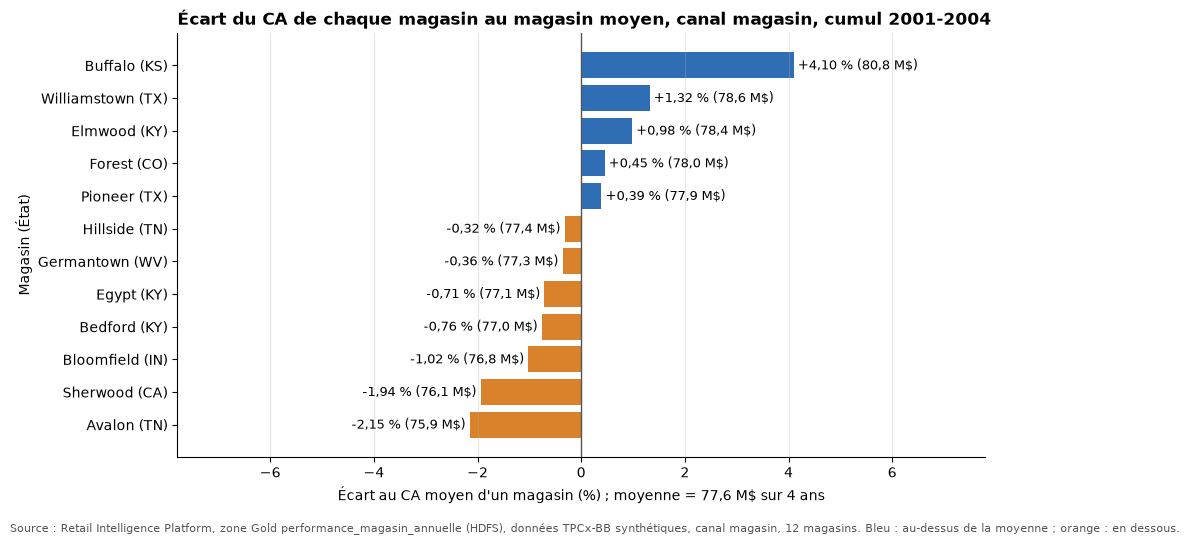

In [17]:
m = mag.sort_values("ecart_moyenne_pct")
couleurs = [BLEU if v >= 0 else ORANGE for v in m["ecart_moyenne_pct"]]
fig, ax = plt.subplots(figsize=(10, 5.4))
barres = ax.barh(m["magasin"], m["ecart_moyenne_pct"], color=couleurs)
for b, v, ca in zip(barres, m["ecart_moyenne_pct"], m["ca_net_paye"]):
    ax.text(v + (0.08 if v >= 0 else -0.08), b.get_y() + b.get_height() / 2,
            f"{'+' if v >= 0 else ''}{fr(v, 2)} % ({fr(ca / 1e6, 1)} M$)", va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color=GRIS, lw=1)
lim = max(abs(m["ecart_moyenne_pct"])) * 1.9
ax.set_xlim(-lim, lim)
ax.set_title("Écart du CA de chaque magasin au magasin moyen, canal magasin, cumul 2001-2004",
             loc="left", fontweight="bold")
ax.set_xlabel(f"Écart au CA moyen d'un magasin (%) ; moyenne = {fr(mag['ca_net_paye'].mean() / 1e6, 1)} M$ sur 4 ans")
ax.set_ylabel("Magasin (État)")
ax.grid(axis="x", alpha=0.3)
fig.text(0.01, 0.005, SOURCE.format("Gold performance_magasin_annuelle") + " Bleu : au-dessus de la moyenne ; orange : en dessous.",
         fontsize=8, color=GRIS)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(VIZ / "ventes_par_magasin.png", dpi=150, bbox_inches="tight")
plt.show()

**Résultats (Q5).**
- Sur 2001-2004, le CA cumulé va de **75,9 M\\$** (Avalon, TN) à **80,8 M\\$** (Buffalo, KS). Les écarts au magasin moyen vont de −2,15 % à +4,10 %, avec un coefficient de variation de **1,67 %** : les magasins sont **très homogènes**.
- Le panier moyen est presque identique partout (12 745 à 13 072 \\$). **Le CA suit le nombre de transactions** (corrélation de 0,88). Buffalo a +4,1 % de CA et +4,1 % de tickets.
- La taille n'explique pas le classement : la corrélation entre CA et effectif est de −0,03. Celle avec la surface est de 0,51, mais elle ne porte que sur 12 magasins, avec des surfaces irréalistes (5,8 à 8,9 millions d'unités, sans unité documentée).
- **Le classement change presque au hasard d'une année à l'autre** : les corrélations de rang (Spearman) entre années vont de −0,42 à 0,52. Williamstown passe du 6e rang au 12e, puis au 3e et au 2e. Avalon passe du 12e au 2e, puis au 8e et au 12e. Seul **Buffalo** reste en tête (3e, puis 1er trois années de suite).

**Interprétation.** Hors Buffalo, les écarts entre magasins relèvent de **fluctuations**, pas d'une différence de performance durable. Buffalo attire plus de transactions, pas des paniers plus gros. Avec ces données, on ne peut pas dire *pourquoi* : il manque les clients, la zone de chalandise et le trafic.

**Limites.** 12 magasins seulement. Les corrélations sur 12 points sont fragiles. Une corrélation ne prouve pas une cause.

## 10. Visualisation complémentaire : distribution du montant des tickets

L'histogramme est calculé **dans Spark**, qui compte les tickets par tranche de 2 000 \\$. Seules les 33 tranches
passent dans Pandas, pas les 89 100 tickets.

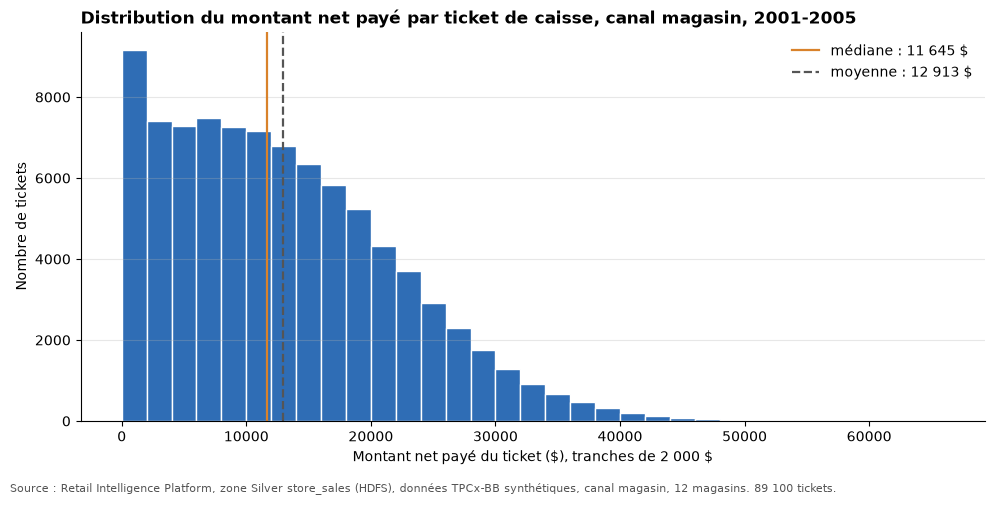

In [18]:
PAS = 2000
distrib = (par_ticket.withColumn("tranche", (F.floor(F.col("montant_ticket") / PAS) * PAS).cast("int"))
           .groupBy("tranche").count().orderBy("tranche")).toPandas()
distrib.to_csv(OUT / "distribution_montant_ticket.csv", index=False, sep=";")
st = statistiques.set_index("variable").loc["montant_ticket"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(distrib["tranche"], distrib["count"], width=PAS, align="edge", color=BLEU, edgecolor="white")
for val, lib, col, ls in [(st["mediane"], "médiane", ORANGE, "-"), (st["moyenne"], "moyenne", GRIS, "--")]:
    ax.axvline(val, color=col, ls=ls, lw=1.6, label=f"{lib} : {fr(val)} $")
ax.set_title("Distribution du montant net payé par ticket de caisse, canal magasin, 2001-2005",
             loc="left", fontweight="bold")
ax.set_xlabel(f"Montant net payé du ticket ($), tranches de {fr(PAS)} $")
ax.set_ylabel("Nombre de tickets")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)
fig.text(0.01, 0.005, SOURCE.format("Silver store_sales") + f" {fr(st['n'])} tickets.", fontsize=8, color=GRIS)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(VIZ / "distribution_montant_ticket.png", dpi=150, bbox_inches="tight")
plt.show()

**Lecture.** La distribution des tickets est **asymétrique à droite** : la médiane est de 11 645 \\$, la moyenne de 12 913 \\$ et le maximum de 64 786 \\$. La première tranche (0 à 2 000 \\$, environ 9 100 tickets) regroupe les tickets d'une ou deux lignes et les tickets entièrement remisés (minimum 0 \\$). Au-delà de 40 000 \\$, les tickets sont rares. Ce graphique justifie de suivre **la médiane** plutôt que la moyenne comme panier « typique ».

## 11. Constats, limites et recommandations (étape 6)

> Rappel : ces constats portent sur des **données synthétiques TPCx-BB**. Ils valident une démarche d'analyse, pas une réalité commerciale.

| # | Résultat observé | Interprétation possible | Limite | Recommandation |
|---|---|---|---|---|
| C1 | CA stable de 2001 à 2004 (±1,1 % par an), sans saisonnalité une fois ramené au nombre de jours. 2005 : −6,5 % sur l'année, mais **−1,5 % à période égale** | Pas de croissance ni de crise. La baisse affichée de 2005 vient surtout de la coupure au 13/12 | Générateur synthétique, canal magasin seul, avant retours | Toujours comparer **à période égale**, et afficher `mois_complet` / `annee_complete` sur les tableaux de bord. Ne pas annoncer « −6,5 % en 2005 » |
| C2 | Music et Books font **72 % du CA**. La part de chaque catégorie suit sa part du catalogue. 6 % des produits font 50 % du CA | La hiérarchie vient du nombre de références, pas du prix ni de la remise (identiques partout) | Pas de marge exploitable, pas de retours, pas de stock dans le Silver | Suivre en priorité la disponibilité des ~1 100 produits qui font la moitié du CA. Juger les catégories au **CA par produit**, pas au CA total |
| C3 | Magasins homogènes (CV de 1,7 %). Le classement annuel est instable, sauf pour **Buffalo** (1er de 2002 à 2004, +4,1 %) | Les écarts sont surtout des fluctuations. Buffalo se distingue par le **nombre de transactions**, pas par le panier | 12 magasins. Pas de donnée de trafic ni de zone de chalandise. Surface non documentée | Ne pas lancer de plan d'action local sur la base d'un seul rang annuel : exiger un écart > 2 % sur 2 années consécutives. Étudier Buffalo avec les données clients (UC-01, Q4) |
| C4 | Panier médian de 11 645 \\$ et 372 articles par ticket | Valeurs **irréalistes** pour un magasin, produites par le générateur | Données synthétiques | Ne pas utiliser ces niveaux comme référence. Seules les **comparaisons relatives** ont un sens |

**KPI non calculés au J4, et pourquoi** :
- canal web et poids des canaux (Q2) : `web_sales` n'a pas été transformé au J3 ;
- taux de retour (KPI-07) : `store_returns` n'est pas en Silver ;
- stock (KPI-08) : `inventory` n'est pas en Silver ;
- marge : 74 % de lignes à marge négative, alerte qualité du J3.

Les valeurs du J1, calculées sur les données brutes, restent disponibles pour ces KPI, mais elles ne sont pas reprises ici sans transformation contrôlée.

In [19]:
import json
resume = {
    "kpi_annee": kpi_annee.to_dict(orient="records"),
    "indice_saisonnier": indice.to_dict(), "indice_par_jour": indice_jour.to_dict(),
    "categories": cat.to_dict(orient="records"),
    "concentration": conc.to_dict(orient="records"), "produits_vendus": n_vendus, "produits_catalogue": n_catalogue,
    "n50": n50,
    "magasins": mag.to_dict(orient="records"), "cv_magasins": cv, "corr_ca_tickets": corr_tickets,
    "spearman": rangs.corr(method="spearman").round(3).to_dict(),
    "statistiques": statistiques.to_dict(orient="records"),
    "reconciliation": {"comparaisons": len(rec), "ecart_max": float(rec["ecart"].abs().max())},
}
(OUT / "resume_uc08.json").write_text(json.dumps(resume, default=str, ensure_ascii=False, indent=1), encoding="utf-8")
print("Fichiers produits :")
for p in sorted(list(OUT.iterdir()) + list(VIZ.iterdir())):
    print(" ", p.relative_to(BASE), f"{p.stat().st_size:,} octets".replace(",", " "))
spark.stop()

Fichiers produits :
  analytics/outputs/analyse1_ca_mensuel.csv 3 742 octets
  analytics/outputs/analyse2_categories.csv 941 octets
  analytics/outputs/analyse2_concentration_produits.csv 82 octets
  analytics/outputs/analyse3_magasins.csv 1 452 octets
  analytics/outputs/distribution_montant_ticket.csv 335 octets
  analytics/outputs/inventaire_jeux.csv 981 octets
  analytics/outputs/kpi.csv 797 octets
  analytics/outputs/kpi_categorie_2004_2005_periode_egale.csv 1 710 octets
  analytics/outputs/kpi_cli.csv 539 octets
  analytics/outputs/reconciliation_j1_j4.csv 1 638 octets
  analytics/outputs/resume_uc08.json 14 609 octets
  analytics/outputs/statistiques.csv 1 027 octets
  analytics/visualizations/ca_par_categorie.png 110 983 octets
  analytics/visualizations/distribution_montant_ticket.png 67 443 octets
  analytics/visualizations/evolution_ventes_mensuelles.png 98 809 octets
  analytics/visualizations/ventes_par_magasin.png 128 382 octets
